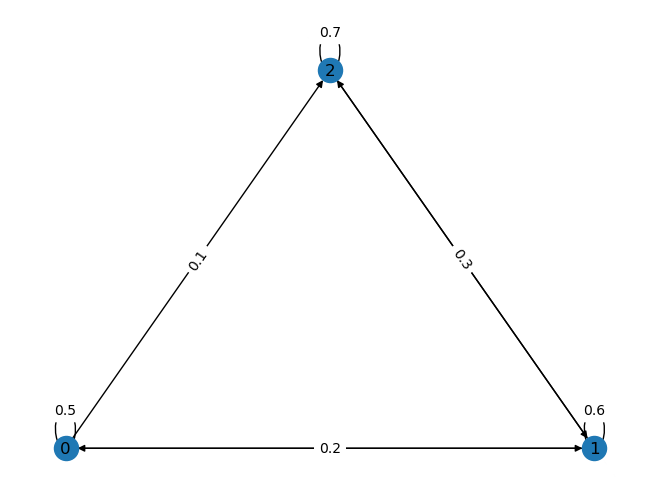

In [16]:
import networkx as nx
import matplotlib.pyplot as plt

P=[[0.5, 0.4, 0.1],
     [0.2, 0.6, 0.2],
     [0.0, 0.3, 0.7]]

G=nx.DiGraph()

for i in range(len(P)):
    for j in range(len(P)):
        if P[i][j] > 0:
            G.add_edge(i, j, weight=P[i][j])

pos=nx.planar_layout(G)

nx.draw(G, pos, with_labels=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))
plt.show()

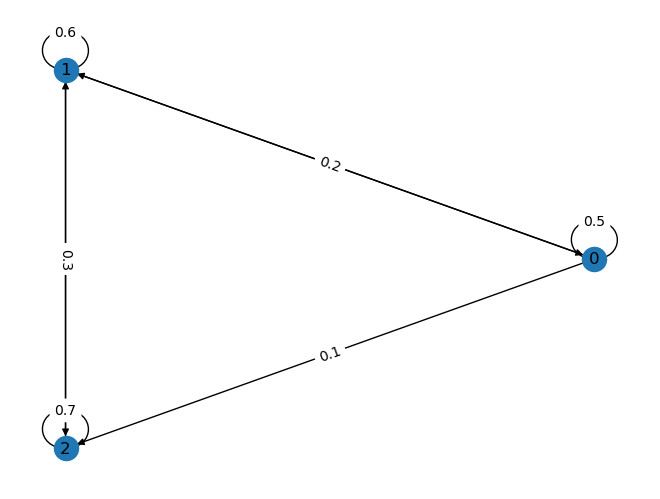

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

P=np.array([[0.5, 0.4, 0.1],
              [0.2, 0.6, 0.2],
              [0.0, 0.3, 0.7]])

G=nx.from_numpy_array(P, create_using=nx.DiGraph)
pos=nx.circular_layout(G)

nx.draw(G, pos, with_labels=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))
plt.show()

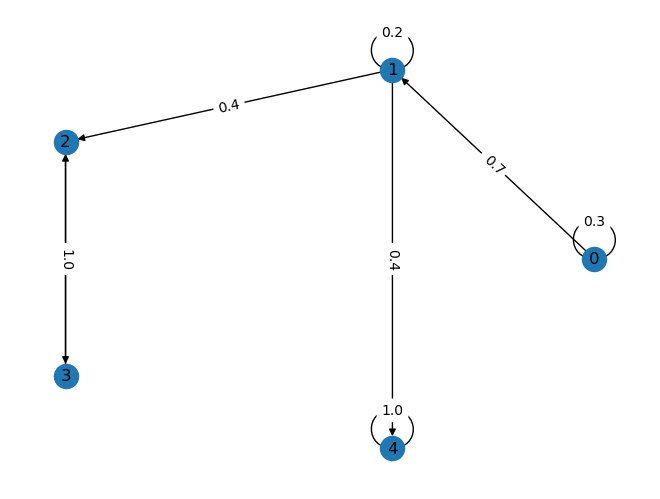

In [3]:
Q=np.array([
    [0.3, 0.7, 0, 0, 0],
    [0, 0.2, 0.4, 0, 0.4],
    [0, 0, 0, 1, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 0, 0, 1]])

G=nx.from_numpy_array(Q, create_using=nx.DiGraph)
pos=nx.circular_layout(G)

nx.draw(G, pos, with_labels=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))
plt.show()

In [4]:
clases=list(nx.strongly_connected_components(G))
print(clases)

[{2, 3}, {4}, {1}, {0}]


In [5]:
for C in clases:
    cerrada=all(j in C for i in C for j in G.successors(i))
    tipo="Recurrente" if cerrada else "Transitoria"
    print(f"Clase {C}: {tipo}")

Clase {2, 3}: Recurrente
Clase {4}: Recurrente
Clase {1}: Transitoria
Clase {0}: Transitoria


In [6]:
list(G.successors(2))

[3]

In [7]:
%pip install pydtmc

Note: you may need to restart the kernel to use updated packages.


In [8]:
from pydtmc import MarkovChain

P=[[0.3, 0.7, 0, 0, 0],
     [0, 0.2, 0.4, 0, 0.4],
     [0, 0, 0, 1, 0],
     [0, 0, 1, 0, 0],
     [0, 0, 0, 0, 1]]

mc=MarkovChain(P)

print("Clases:", mc.communicating_classes)
print("Recurrentes:", mc.recurrent_states)
print("Transitorios:", mc.transient_states)
print("Absorbentes:", mc.absorbing_states)

Clases: [['3', '4'], ['1'], ['2'], ['5']]
Recurrentes: ['3', '4', '5']
Transitorios: ['1', '2']
Absorbentes: ['5']


In [9]:
L=np.array([
    [0.3, 0.7, 0, 0, 0],
    [0, 0.2, 0.4, 0, 0.4],
    [0, 0, 0, 1, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 0, 0, 1]])

mcL=MarkovChain(P)
y=0
h=mc.hitting_probabilities([y])
L @ h

array([0.3, 0. , 0. , 0. , 0. ])

In [17]:
np.column_stack([L @ mc.hitting_probabilities([y]) for y in range(len(P))])

array([[0.3, 1. , 0.5],
       [0. , 0.2, 0.5],
       [0. , 0. , 1. ],
       [0. , 0. , 1. ],
       [0. , 0. , 0. ]])